# Chuẩn bị môi trường

In [ ]:
!pip install easyocr
!pip install ultralytics

In [ ]:
!wget "https://raw.githubusercontent.com/dungnc-uit/computer-vision/refs/heads/main/screenshots/screenshot1_2_3.jpg" -O screenshot1_2_3.jpg
!wget "https://raw.githubusercontent.com/dungnc-uit/computer-vision/refs/heads/main/screenshots/screenshot-01.png" -O screenshot-01.png
!wget "https://github.com/dungnc-uit/computer-vision/raw/refs/heads/main/model/best_v2.pt" -O model.pt

--2025-08-07 06:49:05--  https://raw.githubusercontent.com/dungnc-uit/computer-vision/refs/heads/main/screenshots/screenshot1_2_3.jpg
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 23771 (23K) [image/jpeg]
Saving to: ‘screenshot1_2_3.jpg’

screenshot1_2_3.jpg 100%[===================>]  23.21K  --.-KB/s    in 0.003s  

2025-08-07 06:49:05 (7.82 MB/s) - ‘screenshot1_2_3.jpg’ saved [23771/23771]

--2025-08-07 06:49:05--  https://raw.githubusercontent.com/dungnc-uit/computer-vision/refs/heads/main/screenshots/screenshot-01.png
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request

# Import thư viện

In [ ]:
import cv2
import easyocr
from ultralytics import YOLO
from google.colab.patches import cv2_imshow

# Tải mô hình

In [ ]:
from ultralytics import YOLO

# Load a model
model = YOLO('model.pt')  # load a pretrained model (recommended for training)

# Use the model
model.info()

YOLO11n summary: 181 layers, 2,591,595 parameters, 0 gradients, 6.4 GFLOPs


(181, 2591595, 0, 6.4492031999999995)

# Tải hình ảnh và show kết quả dự đoán

In [ ]:
image = "screenshot1_2_3.jpg"
results = model(image)


image 1/1 /content/screenshot1_2_3.jpg: 640x640 3 Input-Fields, 1 Select-Dropdown, 7 Texts, 1 labelled-buttons, 657.4ms
Speed: 12.3ms preprocess, 657.4ms inference, 2.1ms postprocess per image at shape (1, 3, 640, 640)


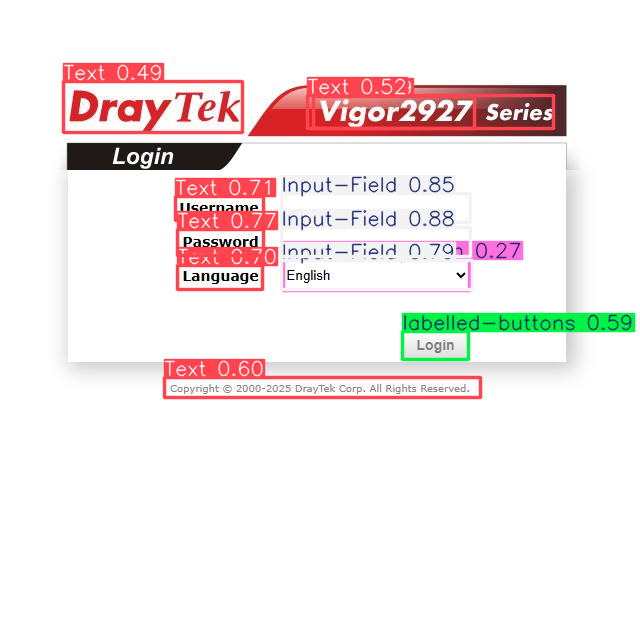

In [ ]:
results[0].show()

# Chương trình chính

## Khai báo class

In [ ]:
class UIDetector:
    """
    Lớp để nhận diện các thành phần giao diện người dùng (UI) từ một ảnh.
    Sử dụng mô hình YOLO để phát hiện đối tượng và EasyOCR để đọc văn bản.
    """
    def __init__(self, model_path):
        """
        Khởi tạo detector.

        Args:
            model_path (str): Đường dẫn đến file trọng số của mô hình YOLO (.pt).
        """
        # Tải mô hình YOLO đã được huấn luyện
        self.model = YOLO(model_path)
        # Khởi tạo trình đọc OCR, chỉ cần chạy một lần
        self.reader = easyocr.Reader(['en'])
        # Danh sách các lớp đối tượng mà mô hình có thể nhận diện
        self.class_names = self.model.names
        print("Mô hình và OCR đã được tải xong.")
        print("Các lớp có thể nhận diện:", self.class_names)


    def detect_elements(self, image_path, confidence_threshold=0.6):
        """
        Phát hiện và trích xuất thông tin từ tất cả các thành phần UI trong ảnh.

        Args:
            image_path (str): Đường dẫn đến ảnh giao diện.
            confidence_threshold (float): Ngưỡng tin cậy để lọc các đối tượng.

        Returns:
            list: Một danh sách các dictionary, mỗi dictionary chứa thông tin về một thành phần.
        """
        # Đọc ảnh
        img = cv2.imread(image_path)
        if img is None:
            print(f"Lỗi: Không thể đọc ảnh từ đường dẫn: {image_path}")
            return []

        # Thực hiện nhận diện đối tượng bằng YOLO
        results = self.model(img)

        detected_elements = []

        # Lặp qua các kết quả nhận diện
        for result in results:
            boxes = result.boxes
            for box in boxes:
                confidence = box.conf[0]
                # Lọc theo ngưỡng tin cậy
                if confidence < confidence_threshold:
                    continue

                # Lấy tọa độ hộp giới hạn (x1, y1, x2, y2)
                x1, y1, x2, y2 = map(int, box.xyxy[0])

                # Lấy nhãn của đối tượng
                class_id = int(box.cls[0])
                label = self.class_names[class_id]

                # Cắt vùng ảnh của đối tượng để thực hiện OCR
                element_img = img[y1:y2, x1:x2]

                # Sử dụng OCR để đọc văn bản trong vùng ảnh đó
                ocr_results = self.reader.readtext(element_img, detail=0, paragraph=True)
                text = " ".join(ocr_results).strip()

                detected_elements.append({
                    'label': label,
                    'coordinates': (x1, y1, x2, y2),
                    'text': text,
                    'confidence': float(confidence)
                })

        return detected_elements

    def find_element(self, detected_elements, target_label, target_text):
        """
        Tìm một thành phần cụ thể dựa trên nhãn và văn bản.

        Args:
            detected_elements (list): Danh sách các thành phần đã được phát hiện.
            target_label (str): Nhãn của thành phần cần tìm (ví dụ: 'input', 'button').
            target_text (str): Văn bản liên quan đến thành phần (ví dụ: 'username', 'login').

        Returns:
            dict or None: Thông tin của thành phần nếu tìm thấy, ngược lại trả về None.
        """
        target_text_lower = target_text.lower()

        # Ưu tiên tìm kiếm văn bản chính xác trên đối tượng
        for element in detected_elements:
            if element['label'] == target_label and target_text_lower in element['text'].lower():
                print(f"Đã tìm thấy '{target_label}' với văn bản chính xác: '{element['text']}'")
                return element

        # Nếu không tìm thấy, tìm kiếm các 'label' (nhãn văn bản) gần đó
        # Đây là một logic đơn giản để tìm mối liên hệ
        target_element = None
        min_distance = float('inf')

        inputs_and_buttons = [el for el in detected_elements if el['label'] == target_label]
        text_labels = [el for el in detected_elements if el['label'] == 'label' and target_text_lower in el['text'].lower()]

        if not text_labels:
            print(f"Không tìm thấy nhãn văn bản nào chứa '{target_text}'.")
            return None

        # Tìm hộp input/button gần nhất với nhãn văn bản
        for ib in inputs_and_buttons:
            for tl in text_labels:
                # Tính khoảng cách giữa tâm của hai đối tượng
                ib_center_x = (ib['coordinates'][0] + ib['coordinates'][2]) / 2
                ib_center_y = (ib['coordinates'][1] + ib['coordinates'][3]) / 2
                tl_center_x = (tl['coordinates'][0] + tl['coordinates'][2]) / 2
                tl_center_y = (tl['coordinates'][1] + tl['coordinates'][3]) / 2

                distance = ((ib_center_x - tl_center_x)**2 + (ib_center_y - tl_center_y)**2)**0.5

                if distance < min_distance:
                    min_distance = distance
                    target_element = ib

        if target_element:
            print(f"Đã tìm thấy '{target_label}' gần nhãn văn bản '{target_text}'.")

        return target_element


## Demo quá trình tìm kiếm tiêu đề vùng cần tìm

In [ ]:
# --- MAIN EXECUTION ---
MODEL_FILE = 'model.pt'
IMAGE_FILE = 'screenshot1_2_3.jpg' # Ảnh chụp màn hình giao diện đăng nhập
TEXT = "username" # Tiêu đề vùng cần tìm

try:
    # Khởi tạo detector
    ui_detector = UIDetector(MODEL_FILE)

    # 1. Phát hiện tất cả các thành phần trong ảnh
    all_elements = ui_detector.detect_elements(IMAGE_FILE)

    print("\n--- Tất cả các thành phần được phát hiện ---")
    for elem in all_elements:
        print(elem)

    # 2. Thực hiện truy vấn: "tìm vị trí của hộp input cho username"
    print("\n--- Thực hiện truy vấn ---")
    query_text = TEXT
    query_label = "Text"

    username_input = ui_detector.find_element(all_elements, query_label, query_text)

    if username_input:
        print(f"\n✅ Kết quả cho truy vấn 'hộp input cho {query_text}':")
        print(f"   - Tọa độ (x1, y1, x2, y2): {username_input['coordinates']}")
        print(f"   - Nhãn: {username_input['label']}")
        print(f"   - Độ tin cậy: {username_input['confidence']:.2f}")
    else:
        print(f"\n❌ Không tìm thấy hộp input nào cho '{query_text}'.")

except FileNotFoundError:
    print(f"\nLỖI: Không tìm thấy file model '{MODEL_FILE}' hoặc file ảnh '{IMAGE_FILE}'.")
except Exception as e:
    print(f"\nĐã xảy ra lỗi không mong muốn: {e}")

Mô hình và OCR đã được tải xong.
Các lớp có thể nhận diện: {0: 'Checkbox', 1: 'Image', 2: 'Input-Field', 3: 'Radio-Button', 4: 'Search-Box', 5: 'Select-Dropdown', 6: 'Text', 7: 'icon', 8: 'labelled-buttons'}

0: 640x640 3 Input-Fields, 1 Select-Dropdown, 7 Texts, 1 labelled-buttons, 225.4ms
Speed: 3.9ms preprocess, 225.4ms inference, 1.3ms postprocess per image at shape (1, 3, 640, 640)

--- Tất cả các thành phần được phát hiện ---
{'label': 'Input-Field', 'coordinates': (281, 227, 470, 256), 'text': '', 'confidence': 0.8753089904785156}
{'label': 'Input-Field', 'coordinates': (281, 193, 470, 222), 'text': '', 'confidence': 0.8450523018836975}
{'label': 'Input-Field', 'coordinates': (281, 260, 472, 289), 'text': 'English', 'confidence': 0.7880890965461731}
{'label': 'Text', 'coordinates': (177, 229, 263, 255), 'text': 'Password', 'confidence': 0.7705018520355225}
{'label': 'Text', 'coordinates': (175, 196, 263, 220), 'text': 'Username', 'confidence': 0.7088020443916321}
{'label': 'Text

## Demo tìm kiếm vùng nhập liệu ứng với tiêu đề


--- Tìm Input-Field gần nhất với Username ---

✅ Đã tìm thấy Input-Field gần nhất với Username:
   - Tọa độ (x1, y1, x2, y2): (281, 193, 470, 222)
   - Nhãn: Input-Field
   - Độ tin cậy: 0.85

--- Hình minh họa kết quả ---


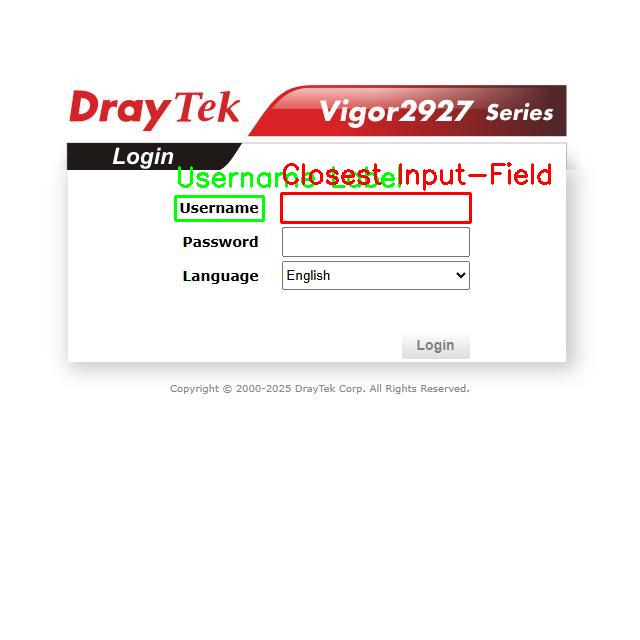

In [ ]:
# 3. Tìm "Input-Field" gần nhất với "username_input"
print("\n--- Tìm Input-Field gần nhất với Username ---")

# Lấy tọa độ của username_input (label 'Text' với văn bản 'Username')
if username_input:
    username_label_coords = username_input['coordinates']
    username_label_center_x = (username_label_coords[0] + username_label_coords[2]) / 2
    username_label_center_y = (username_label_coords[1] + username_label_coords[3]) / 2

    closest_input_field = None
    min_distance = float('inf')

    # Lọc ra tất cả các đối tượng có nhãn 'Input-Field'
    input_fields = [el for el in all_elements if el['label'] == 'Input-Field']

    if input_fields:
        # Tìm Input-Field gần nhất với tâm của username_input label
        for input_field in input_fields:
            input_coords = input_field['coordinates']
            input_center_x = (input_coords[0] + input_coords[2]) / 2
            input_center_y = (input_coords[1] + input_coords[3]) / 2

            distance = ((username_label_center_x - input_center_x)**2 + (username_label_center_y - input_center_y)**2)**0.5

            if distance < min_distance:
                min_distance = distance
                closest_input_field = input_field

        if closest_input_field:
            print(f"\n✅ Đã tìm thấy Input-Field gần nhất với Username:")
            print(f"   - Tọa độ (x1, y1, x2, y2): {closest_input_field['coordinates']}")
            print(f"   - Nhãn: {closest_input_field['label']}")
            print(f"   - Độ tin cậy: {closest_input_field['confidence']:.2f}")

            # 4. Vẽ hình minh họa kết quả tìm thấy
            img_display = cv2.imread(IMAGE_FILE)

            # Vẽ hộp giới hạn cho username_input label (màu xanh lá cây)
            x1_label, y1_label, x2_label, y2_label = username_label_coords
            cv2.rectangle(img_display, (x1_label, y1_label), (x2_label, y2_label), (0, 255, 0), 2)
            cv2.putText(img_display, 'Username Label', (x1_label, y1_label - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.9, (0, 255, 0), 2)

            # Vẽ hộp giới hạn cho Input-Field gần nhất (màu đỏ)
            x1_input, y1_input, x2_input, y2_input = closest_input_field['coordinates']
            cv2.rectangle(img_display, (x1_input, y1_input), (x2_input, y2_input), (0, 0, 255), 2)
            cv2.putText(img_display, 'Closest Input-Field', (x1_input, y1_input - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.9, (0, 0, 255), 2)

            # Hiển thị ảnh kết quả
            print("\n--- Hình minh họa kết quả ---")
            cv2_imshow(img_display)

        else:
            print("\n❌ Không tìm thấy Input-Field nào trong ảnh.")
    else:
        print("\n❌ Không tìm thấy Input-Field nào trong ảnh.")

else:
    print("\n❌ Không tìm thấy Username label trong ảnh.")